# فصل دهم: تشخیص ناهنجاری — اجرای مستقل و بازتولیدپذیر

همهٔ داده‌ها ساختگی هستند. در این دفترچه، امتیاز بزرگ‌تر به معنی نمونهٔ غیرعادی‌تر است؛ **امتیاز مساوی احتمال تقلب نیست**.

## ۱. واردکردن کتابخانه‌ها و خواندن داده
فقط NumPy، Matplotlib و فایل محلی `chapter10_examples.py` لازم است.

In [1]:
import csv, json, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
import chapter10_examples as ex
D=Path.cwd()
rows=list(csv.DictReader((D/"events_synthetic.csv").open(encoding="utf8")))
len(rows), rows[0]

(300,
 {'event_id': '0',
  'account_id': '0',
  'peer_group': 'retail',
  'hour': '10',
  'amount': '47.28',
  'synthetic_truth_for_evaluation_only': '0'})

## ۲. نمونهٔ دستی و برآورد مقاوم
برای مثال ۱۰، میانهٔ ۱۲٫۵ و MAD برابر ۱٫۵ است.

In [2]:
sample=np.array([10,11,11,12,12,13,13,14,15,48])
median=np.median(sample);mad=np.median(abs(sample-median))
print("median", median, "MAD", mad, "robust z(48)",ex.robust_z([48],sample)[0]);assert abs(ex.robust_z([48],sample)[0]-15.9629241)<1e-4

median 12.5 MAD 1.5 robust z(48) 15.962924087973933


## ۳. مقایسهٔ حساسیت میانگین و میانه

In [3]:
print("mean with outlier", np.mean(sample), "mean without", np.mean(sample[:-1]), "median",median)
assert np.mean(sample)==15.9

mean with outlier 15.9 mean without 12.333333333333334 median 12.5


## ۴. حصار Tukey
برای این مثال مرز بالایی ۱۷٫۵ است.

In [4]:
low,high=ex.tukey_bounds(sample)
print("bounds",low,high, "flagged:",sample[(sample<low)|(sample>high)].tolist())
assert (low,high)==(7.5,17.5)

bounds 7.5 17.5 flagged: [48]


## ۵. فاصلهٔ همسایهٔ دوم برای نمونهٔ جدید

In [5]:
ref=np.array([[0],[1],[2],[3],[4]])
print("k=2 scores",ex.k_neighbor_scores([[7],[2.5]],ref,k=2));assert np.allclose(ex.k_neighbor_scores([[7],[2.5]],ref,k=2),[4,.5])

k=2 scores [4.  0.5]


## ۶. LOF با دقیقاً دو همسایه و قاعدهٔ تساویِ ورودی

[1.25       1.25       0.66666667 1.25       1.25       9.66666667]


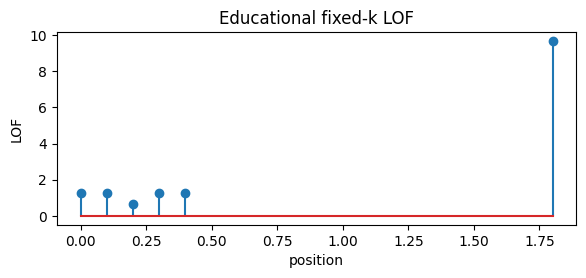

In [6]:
points=np.array([0,.1,.2,.3,.4,1.8])
lof=ex.lof_fixed_k(points[:,None],k=2);print(lof);assert np.isclose(lof[-1],9.6666666667)
fig,ax=plt.subplots(figsize=(6.7,2.5));ax.stem(points,lof);ax.set(xlabel="position",ylabel="LOF",title="Educational fixed-k LOF");plt.show()

## ۷. فاصلهٔ ماهالانوبیس و کوواریانس نزدیک به تکین

In [7]:
r=np.array([[0,0],[1,1],[2,2],[3,3]],float)
score=ex.mahalanobis_scores([[6,6]],r,regularization=.1)
print("regularized Mahalanobis",score.tolist());assert np.isfinite(score).all()

regularized Mahalanobis [3.4345474963747984]


## ۸. مثال زمینه‌ای
مرجع فقط ۲۰۰ رویداد اول است؛ از حقیقت ساختگی برای برازش امتیاز استفاده نمی‌کنیم.

In [8]:
amount=np.array([float(r["amount"]) for r in rows]);groups=np.array([r["peer_group"] for r in rows]);truth=np.array([int(r["synthetic_truth_for_evaluation_only"]) for r in rows]);reference=np.arange(len(rows))<200
scores=ex.contextual_score(amount,groups,amount[reference],groups[reference]);print("score range",float(scores.min()),float(scores.max()),"positives",int(truth.sum()))

score range 0.03500000000000014 1466.82 positives 15


## ۹. رتبه‌بندیِ ظرفیت محدود بررسی

In [9]:
for k in [5,10,15,30]:print("k",k,ex.precision_recall_at_k(truth,scores,k))
assert ex.precision_recall_at_k(truth,scores,15)["hits"]==10

k 5 {'hits': 4, 'precision_at_k': 0.8, 'recall_at_k': 0.26666666666666666}
k 10 {'hits': 8, 'precision_at_k': 0.8, 'recall_at_k': 0.5333333333333333}
k 15 {'hits': 10, 'precision_at_k': 0.6666666666666666, 'recall_at_k': 0.6666666666666666}
k 30 {'hits': 14, 'precision_at_k': 0.4666666666666667, 'recall_at_k': 0.9333333333333333}


## ۱۰. نمایشِ امتیاز و برچسب فقط برای ارزیابی

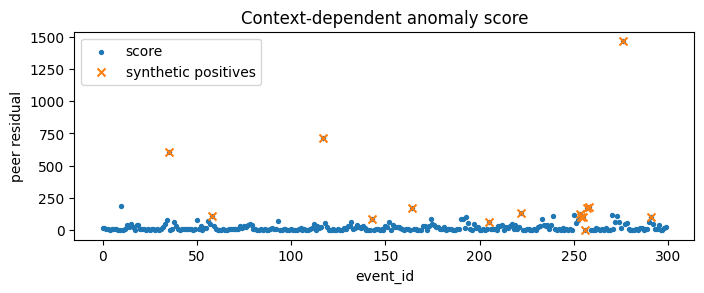

In [10]:
fig,ax=plt.subplots(figsize=(8,2.7));ax.scatter(np.arange(len(rows)),scores,s=8,label="score");ax.scatter(np.where(truth)[0],scores[truth==1],marker="x",s=33,label="synthetic positives");ax.set(xlabel="event_id",ylabel="peer residual",title="Context-dependent anomaly score");ax.legend();plt.show()

## ۱۱. ناهنجاری جمعی و پنجرهٔ علّی

In [11]:
s=json.loads((D/"signals_synthetic.json").read_text());z=s["collective_shift"];print("rolling",ex.scan_window_mean(z,3));print("CUSUM",ex.positive_cusum(z,drift=.25))
assert np.isnan(ex.scan_window_mean(z,3)[0])

rolling [           nan            nan 6.66666667e-02 9.25185854e-18
 6.00000000e-01 1.00000000e+00 1.60000000e+00 1.56666667e+00]
CUSUM [0.   0.   0.15 0.   1.25 2.6  4.05 5.2 ]


## ۱۲. بررسی آستانه و تفکیک FP/FN

In [12]:
threshold=float(np.quantile(scores,.95));print("threshold",threshold, "confusion",ex.confusion_at_threshold(truth,scores,threshold));assert np.isfinite(threshold)

threshold 103.44850000000001 confusion {'TP': 10, 'FP': 5, 'FN': 5, 'TN': 280}


## ۱۳. صحت داده و بازتولید آزمایش (سلول اجرایی دوازدهم)
نکته: ستون حقیقت صرفاً برای ارزیابی استفاده شده؛ انتخاب آستانهٔ واقعی به اعتبارسنجی مستقل نیاز دارد.

In [13]:
reference_result=ex.demonstration();print(json.dumps(reference_result,indent=2,ensure_ascii=False));assert reference_result["contextual_precision_at_15"]["hits"]==10;assert len(ex.make_synthetic())==300

{
  "median": 12.5,
  "mad": 1.5,
  "robust_z_48": 15.962924087973933,
  "iqr_bounds": [
    7.5,
    17.5
  ],
  "fixed_k_lof": [
    1.25,
    1.25,
    0.666667,
    1.25,
    1.25,
    9.666667
  ],
  "contextual_precision_at_15": {
    "hits": 10,
    "precision_at_k": 0.6666666666666666,
    "recall_at_k": 0.6666666666666666
  },
  "anomaly_count": 15,
  "count": 300
}
